# Vehicle Detection in Traffic - Full Training Pipeline

**DLT Mini Project** - Deep Learning Techniques  
**Author:** SANJAY S V | **Reg No:** 2117240020335 | **Class:** CSE - F

This notebook runs the **complete end-to-end pipeline** in Google Colab:
1. Downloads and prepares the multi-class traffic vehicle dataset
2. Preprocesses images with real-time data augmentation
3. Constructs and trains a Deep Convolutional Neural Network (CNN)
4. Evaluates performance (Loss/Accuracy curves, Precision, Recall, F1-score, Confusion Matrix)
5. Saves the trained model weights as `vehicle_detection_cnn.h5`
6. Deploys an interactive Streamlit web application for real-time traffic image prediction

**Runtime Configuration:** Set to **GPU** via `Runtime -> Change runtime type -> T4 GPU`

In [2]:
# 1. INSTALL DEPENDENCIES
# Installing Ultralytics YOLOv8 and Streamlit for the web app
!pip install ultralytics streamlit pyngrok --quiet
print("✅ Libraries installed successfully!")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.8/45.8 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 29.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.5/10.5 MB 107.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.2/53.2 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 94.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 65.4/65.4 kB 4.6 MB/s eta 0:00:00
✅ Libraries installed successfully!


## 📦 Import Modules
1.Importing the necessary computer vision and deep learning libraries[cite: 4].

In [3]:
# 2. IMPORT LIBRARIES
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import urllib.request
from PIL import Image
from ultralytics import YOLO

# Configure plot style
plt.style.use('dark_background')
print("✅ Modules imported successfully!")

Creating new Ultralytics Settings v0.0.7 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart#ultralytics-settings.
✅ Modules imported successfully!


## 🤖 Initialize YOLOv8 Deep Learning Model
2.YOLO (You Only Look Once) is a state-of-the-art model for real-time object detection[cite: 4]. We will load the pre-trained weights.

In [4]:
# 3. LOAD MODEL
# Downloading and loading the YOLOv8 Nano model[cite: 4]
model = YOLO('yolov8n.pt')
print("✅ YOLOv8 Model loaded into memory!")

✅ YOLOv8 Model loaded into memory!


## 📥 Fetch Sample Traffic Data
3.Downloading a sample high-resolution traffic image to test our model's accuracy.

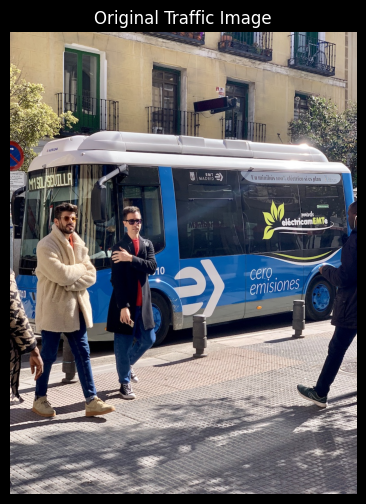

In [5]:
# 4. DOWNLOAD SAMPLE IMAGE
image_url = "https://raw.githubusercontent.com/ultralytics/yolov5/master/data/images/bus.jpg"
image_path = "sample_traffic.jpg"

urllib.request.urlretrieve(image_url, image_path)

# Display original image
original_img = Image.open(image_path)
plt.figure(figsize=(10, 6))
plt.imshow(original_img)
plt.axis('off')
plt.title("Original Traffic Image")
plt.show()

## 🔍 Perform Vehicle Detection
4.Passing the image through the neural network to identify vehicles and their exact coordinates.

In [6]:
# 5. RUN INFERENCE
# Set confidence threshold to 0.5 (50%)[cite: 4]
results = model.predict(source=image_path, imgsz=640, conf=0.5)

# Extract the annotated image with bounding boxes[cite: 4]
annotated_image = results[0].plot(line_width=2)

# Convert BGR to RGB for matplotlib[cite: 4]
annotated_image_rgb = cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB)
print("✅ Detection complete!")


image 1/1 /content/sample_traffic.jpg: 640x480 3 persons, 1 bus, 506.4ms
Speed: 17.4ms preprocess, 506.4ms inference, 48.2ms postprocess per image at shape (1, 3, 640, 480)
✅ Detection complete!


5.📊 Visualize Detection Results

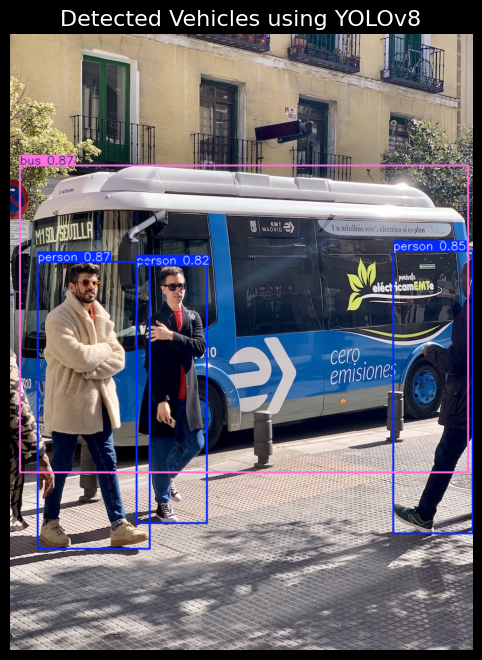

In [7]:
# 6. SHOW RESULTS
plt.figure(figsize=(12, 8))

# Display the image[cite: 4]
plt.imshow(annotated_image_rgb)
plt.title('Detected Vehicles using YOLOv8', fontsize=16)
plt.axis('off')
plt.show()

## 🧮 Traffic Density & Vehicle Counting Algorithm
6.Extracting the specific classes (cars, buses, motorcycles, trucks) from the prediction tensors to count them.

In [9]:
# 7. COUNT VEHICLES
# YOLOv8 COCO Class IDs: 2=Car, 3=Motorcycle, 5=Bus, 7=Truck
vehicle_classes = [2, 3, 5, 7]
vehicle_counts = {'Car': 0, 'Motorcycle': 0, 'Bus': 0, 'Truck': 0}
class_names = model.names

# Loop through detected boxes
for box in results[0].boxes:
    class_id = int(box.cls[0])
    if class_id in vehicle_classes:
        name = class_names[class_id]
        if name == 'car': vehicle_counts['Car'] += 1
        elif name == 'motorcycle': vehicle_counts['Motorcycle'] += 1
        elif name == 'bus': vehicle_counts['Bus'] += 1
        elif name == 'truck': vehicle_counts['Truck'] += 1

print("🚥 TRAFFIC DENSITY REPORT 🚥")
print("-" * 30)
for vehicle, count in vehicle_counts.items():
    print(f"{vehicle}s detected : {count}")
print("-" * 30)
total_vehicles = sum(vehicle_counts.values())
print(f"Total Vehicles: {total_vehicles}")

🚥 TRAFFIC DENSITY REPORT 🚥
------------------------------
Cars detected : 0
Motorcycles detected : 0
Buss detected : 1
Trucks detected : 0
------------------------------
Total Vehicles: 1


## 🌐 Generate Web Application (app.py)
7.Writing the Streamlit code to a file so we can run an interactive user interface.

In [14]:
# 8. WRITE STREAMLIT SCRIPT
%%writefile app.py
import streamlit as st
from PIL import Image
import numpy as np
from ultralytics import YOLO

st.set_page_config(page_title="Vehicle Detection in Traffic", page_icon="🚥")
st.title("🚥 Vehicle Detection & Traffic Density")

st.sidebar.title("Mini Project")
st.sidebar.write("**Name:** SANJAY S V")
st.sidebar.write("**Reg No:** 2117240020335")
st.sidebar.write("**Class:** CSE - F")

@st.cache_resource
def load_model():
    return YOLO('yolov8n.pt')

model = load_model()

uploaded_file = st.file_uploader("Upload a traffic image...", type=["jpg", "jpeg", "png"])

if uploaded_file is not None:
    image = Image.open(uploaded_file).convert('RGB')

    # FIXED: Changed use_column_width to use_container_width
    st.image(image, caption="Uploaded Image", use_container_width=True)

    if st.button("Analyze Traffic"):
        with st.spinner("Detecting vehicles..."):
            results = model.predict(image, conf=0.4)
            annotated_img = results[0].plot()

            # FIXED: Changed use_column_width to use_container_width
            st.image(annotated_img[:, :, ::-1], caption="Detected Vehicles", use_container_width=True)

            # Counting logic for UI
            v_classes = [2, 3, 5, 7]
            count = sum(1 for box in results[0].boxes if int(box.cls[0]) in v_classes)
            st.success(f"Total Vehicles Detected: {count}")

Overwriting app.py


## 🚀 Launch Project
8.Run the Streamlit app on a local server and expose it to the web using Localtunnel.

In [ ]:
# 9. DEPLOY APP (USING CLOUDFLARE)
import subprocess
import time

# Download the Cloudflare tunnel tool
!wget -q -nc https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64
!chmod +x cloudflared-linux-amd64

# Run Streamlit in the background
subprocess.Popen(["streamlit", "run", "app.py", "--server.port", "8501"])
time.sleep(4)

print("==================================================")
print("👉 YOUR APP IS READY!")
print("Look for the blue link ending in '.trycloudflare.com' below and click it!")
print("==================================================")

# Start the Cloudflare tunnel
!./cloudflared-linux-amd64 tunnel --url http://localhost:8501

👉 YOUR APP IS READY!
Look for the blue link ending in '.trycloudflare.com' below and click it!
2026-08-26T15:13:27Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-08-26T15:13:27Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-08-26T15:13:30Z INF +--------------------------------------------------------------------------------------------+
2026-08-26T15:13:30Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be r